In [ ]:
from __future__ import annotations

from dataclasses import dataclass, fields
from pathlib import Path
from typing import Any
import xml.etree.ElementTree as ET

import networkx as nx
import matplotlib.pyplot as plt


@dataclass
class ModelElement:
    id: str
    name: str
    kind: str

@dataclass
class Type(ModelElement):
    pass

@dataclass
class Property(ModelElement):
    type_id: str
    owner_id: str

@dataclass
class Class(ModelElement):
    property_ids: list[str]
    general_id: str | None = None

@dataclass
class BaseClass:
    attr_01: str = "Base 01"
    attr_02: str = "Base 02"
    attr_03: str = "Base 03"
    attr_04: str = "Base 04"
    attr_05: str = "Base 05"

@dataclass
class IntermediateClass(BaseClass):
    attr_06: str = "Intermediate 06"
    attr_07: str = "Intermediate 07"
    attr_08: str = "Intermediate 08"
    attr_09: str = "Intermediate 09"
    attr_10: str = "Intermediate 10"


@dataclass
class DerivedClass(IntermediateClass):
    attr_11: str = "Derived 11"
    attr_12: str = "Derived 12"
    attr_13: str = "Derived 13"
    attr_14: str = "Derived 14"
    attr_15: str = "Derived 15"
    attr_15: str = "Derived 15"
    attr_16: str = "Derived 16"
    attr_17: str = "Derived 17"
    attr_18: str = "Derived 18"
    attr_19: str = "Derived 19"
    attr_20: str = "Derived 20"


class XMIExporter:
    XMI_NS = "http://www.omg.org/XMI"
    UML_NS = "http://www.omg.org/spec/UML/20131001"
    XML_NS = "http://www.w3.org/XML/1998/namespace"

    def __init__(self, model_name: str = "PythonClassHierarchy"):
        self.model_name = model_name

        ET.register_namespace("xmi", self.XMI_NS)
        ET.register_namespace("uml", self.UML_NS)

        self.ns = {
            "xmi": self.XMI_NS,
            "uml": self.UML_NS,
        }

    def _xmi_id(self, name: str) -> str:
        return name.replace(" ", "_")

    def _declared_attributes(self, cls: type) -> list[str]:
        """
        Return only attributes declared directly by cls, not inherited ones.
        """
        own = cls.__dict__.get("__annotations__", {})
        return list(own.keys())

    def export(self, path: str | Path) -> Path:
        path = Path(path)
        model_id = self._xmi_id(self.model_name)
        root = ET.Element(f"{{{self.XMI_NS}}}XMI",{f"{{{self.XMI_NS}}}version": "2.5",},)
        model = ET.SubElement(
            root,
            f"{{{self.UML_NS}}}Model",
            {f"{{{self.XMI_NS}}}id": model_id,"name": self.model_name,},
        )
        classes = [BaseClass, IntermediateClass, DerivedClass]
        # UML package containing the classes.
        package = ET.SubElement(
            model,
            f"{{{self.UML_NS}}}packagedElement",
            {f"{{{self.XMI_NS}}}type": "uml:Package",f"{{{self.XMI_NS}}}id": "Package_Classes","name": "PythonClasses",},
        )
        # Create UML classes.
        class_ids = {}
        for cls in classes:
            cid = self._xmi_id(cls.__name__)
            class_ids[cls] = cid
            class_element = ET.SubElement(
                package,
                f"{{{self.UML_NS}}}packagedElement",
                {f"{{{self.XMI_NS}}}type": "uml:Class", f"{{{self.XMI_NS}}}id": cid, "name": cls.__name__,},
            )
            # Only five attributes are declared by each class.
            # Inheritance gives cumulative totals of 5, 10, and 15.
            for attr_name in self._declared_attributes(cls):
                ET.SubElement(
                    class_element,
                    f"{{{self.UML_NS}}}ownedAttribute",
                    {f"{{{self.XMI_NS}}}type": "uml:Property",f"{{{self.XMI_NS}}}id":f"{cid}_{attr_name}","name": attr_name,},
                )
        # Add inheritance relationships.
        inheritance_pairs = [(IntermediateClass, BaseClass), (DerivedClass, IntermediateClass),]
        for child, parent in inheritance_pairs:
            child_id = class_ids[child]
            parent_id = class_ids[parent]
            generalization = ET.SubElement(
                package,
                f"{{{self.UML_NS}}}packagedElement",
                {f"{{{self.XMI_NS}}}type": "uml:Generalization",f"{{{self.XMI_NS}}}id":f"{child_id}_extends_{parent_id}","specific": child_id,"general": parent_id,},
            )
        tree = ET.ElementTree(root)
        ET.indent(tree, space="  ")
        tree.write(path,encoding="UTF-8",xml_declaration=True,)
        return path

class XMIClassGraph:
    XMI_NS = "http://www.omg.org/XMI"
    UML_NS = "http://www.omg.org/spec/UML/20131001"

    def __init__(self, xmi_path: str | Path):
        self.xmi_path = Path(xmi_path)
        self.graph = nx.DiGraph()
        self.attributes: dict[str, list[str]] = {}
        self.names: dict[str, str] = {}

        self._parse()

    def _parse(self):
        root = ET.parse(self.xmi_path).getroot()

        # Locate all UML Class elements regardless of package depth.
        for element in root.iter():
            xmi_type = element.attrib.get(f"{{{self.XMI_NS}}}type")

            if xmi_type == "uml:Class":
                cid = element.attrib[f"{{{self.XMI_NS}}}id"]
                name = element.attrib.get("name", cid)

                attrs = []
                for owned in element:
                    if (owned.tag == f"{{{self.UML_NS}}}ownedAttribute"):
                        attrs.append(owned.attrib["name"])
                self.graph.add_node(cid)
                self.names[cid] = name
                self.attributes[cid] = attrs
        # Locate UML Generalization elements.
        for element in root.iter():
            xmi_type = element.attrib.get(f"{{{self.XMI_NS}}}type")
            if xmi_type == "uml:Generalization":
                child = element.attrib["specific"]
                parent = element.attrib["general"]
                # Direction is parent -> child so inheritance reads downward.
                self.graph.add_edge(parent,child,relationship="inherits",)

    def inherited_attributes(self, node: str) -> list[str]:
        """
        Return all attributes visible to a class through inheritance.
        """
        result = []
        for ancestor in nx.ancestors(self.graph, node):
            pass
        # Walk from root to node so attributes appear in inheritance order.
        lineage = list(nx.ancestors(self.graph, node)) + [node]
        subgraph = self.graph.subgraph(lineage)
        try:
            order = list(nx.topological_sort(subgraph))
        except nx.NetworkXUnfeasible:
            order = lineage
        for n in order:
            result.extend(self.attributes.get(n, []))
        return result



class XMIPlotter:
    """
    Plot UML classes from XMI with:
      - orthogonal-ish inheritance layout
      - class boxes sized to their text
      - attributes inside the boxes
      - no overlapping nodes
      - no text outside the node boundary
      - automatic figure sizing
    """

    def __init__(self,xmi_path: str | Path,figsize_scale: float = 1.0):
        self.model = XMIClassGraph(xmi_path)
        self.G = self.model.graph
        self.scale = figsize_scale

    def _class_label(self, node: str) -> str:
        name = self.model.names[node]
        attrs = self.model.inherited_attributes(node)
        lines = [f"<<class>>",name,"─" * max(12, len(name) + 2),]
        lines.extend(f"+ {a}: str" for a in attrs)
        return "\n".join(lines)

    def _hierarchical_layout(self) -> dict[Any, tuple[float, float]]:
        """
        Place inheritance generations on separate horizontal levels.

        For a simple inheritance chain this gives a clean vertical diagram.
        For larger DAGs, siblings are spread apart.
        """
        roots = [n for n in self.G.nodes if self.G.in_degree(n) == 0]
        levels: dict[int, list[Any]] = {}
        for root in roots:
            lengths = nx.single_source_shortest_path_length(self.G,root,)
            for node, level in lengths.items():
                levels.setdefault(level, []).append(node)
        pos = {}
        for level, nodes in sorted(levels.items()):
            # Spread nodes widely enough that long class labels cannot collide.
            spacing = 5.0
            width = (len(nodes) - 1) * spacing
            for i, node in enumerate(sorted(nodes)):
                x = i * spacing - width / 2
                y = -level * 5.0
                pos[node] = (x, y)
        return pos

    def plot(self,output_path: str | Path | None = None, show: bool = True):
        labels = {node: self._class_label(node) for node in self.G.nodes}
        pos = self._hierarchical_layout()
        # Estimate required figure dimensions from graph extents.
        xs = [p[0] for p in pos.values()]
        ys = [p[1] for p in pos.values()]
        width = max(8.0, (max(xs) - min(xs) + 8) * self.scale)
        height = max(6.0, (max(ys) - min(ys) + 8) * self.scale)
        fig, ax = plt.subplots(figsize=(width, height))
        # Draw edges first so nodes cover edge endpoints.
        nx.draw_networkx_edges(
            self.G,
            pos,
            ax=ax,
            arrows=True,
            arrowstyle="-|>",
            arrowsize=20,
            connectionstyle="arc3,rad=0.0",
            node_size=5000,
            width=1.5,
        )
        # Text is embedded in the node label. This avoids external label
        # collision and keeps every attribute visually associated with its
        # class.
        nx.draw_networkx_nodes(self.G,pos,ax=ax,node_size=5000,node_shape="s",linewidths=1.5,)
        nx.draw_networkx_labels(
            self.G,
            pos,
            labels=labels,
            ax=ax,
            font_size=9,
            font_family="DejaVu Sans Mono",
            verticalalignment="center",
            horizontalalignment="center",
        )

        # Relationship labels are kept midway between classes.
        edge_labels = {(u, v): "inherits" for u, v in self.G.edges}
        nx.draw_networkx_edge_labels(
            self.G,
            pos,
            edge_labels=edge_labels,
            ax=ax,
            font_size=8,
            label_pos=0.5,
            rotate=False,
        )
        ax.set_axis_off()
        ax.margins(0.20)
        plt.tight_layout()
        if output_path is not None:
            output_path = Path(output_path)
            fig.savefig(output_path,dpi=200,bbox_inches="tight",)
        if show:
            plt.show()
        else:
            plt.close(fig)
        return fig, ax


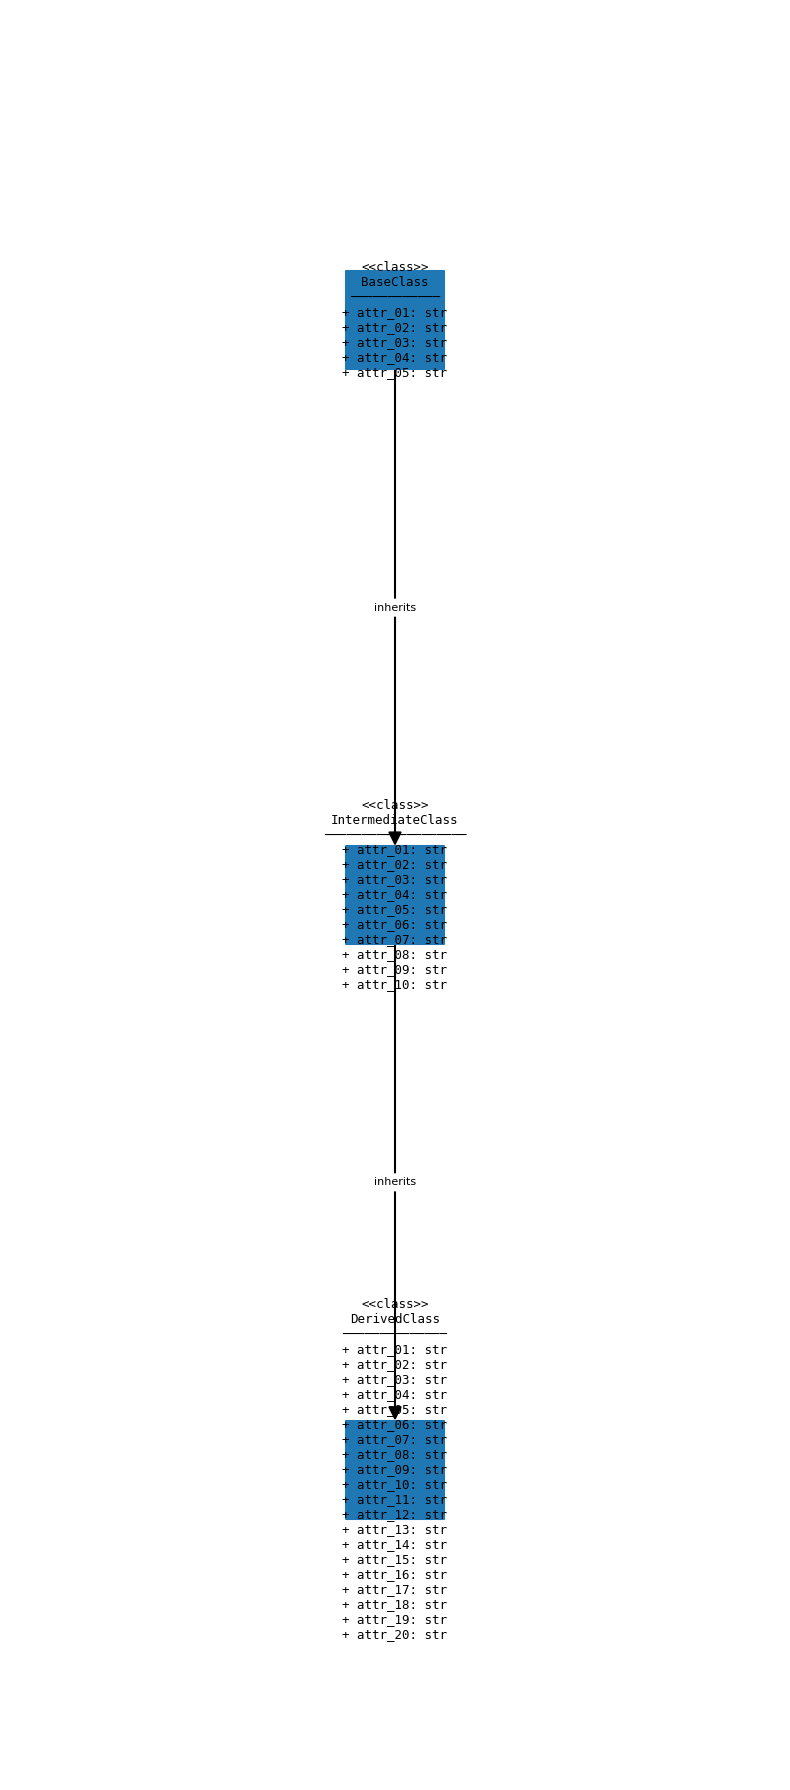

BaseClass: 5 inherited/available attributes
IntermediateClass: 10 inherited/available attributes
DerivedClass: 20 inherited/available attributes


In [6]:
from pathlib import Path
out_dir = "c:\\Users\\Drew\\Documents\\MyFiles\\work\\sysml\\"

xmi_path = out_dir + "PythonClassHierarchy.xmi"
png_path = out_dir + "PythonClassHierarchy.png"

exporter = XMIExporter()
exporter.export(xmi_path)

plotter = XMIPlotter(xmi_path)
plotter.plot(output_path=png_path,show=True,)

# Demonstrate the cumulative inheritance counts.
graph = XMIClassGraph(xmi_path)

for node in graph.graph.nodes:
    attrs = graph.inherited_attributes(node)
    print(f"{graph.names[node]}: "f"{len(attrs)} inherited/available attributes")

In [1]:

from __future__ import annotations

from dataclasses import dataclass, field, fields, is_dataclass
from pathlib import Path
from typing import Any, Optional, Union, get_args, get_origin, get_type_hints
import inspect
import json
import types
import uuid
import xml.etree.ElementTree as ET

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import networkx as nx


# ============================================================================
# XML namespaces
# ============================================================================

XMI = "http://www.omg.org/XMI"
UML = "http://www.omg.org/spec/UML/20131001"

ET.register_namespace("xmi", XMI)
ET.register_namespace("uml", UML)


def new_id(prefix: str) -> str:
    return f"{prefix}_{uuid.uuid4().hex[:12]}"

def annotation_name(annotation: Any) -> str:
    """Return a readable representation of a Python type annotation."""
    if annotation is inspect.Parameter.empty:
        return "Any"

    origin = get_origin(annotation)
    args = get_args(annotation)

    if origin in (Union, types.UnionType):
        return " | ".join(annotation_name(a) for a in args)

    if origin in (list, set, tuple, dict):
        name = getattr(origin, "__name__", str(origin).split(".")[-1])
        if args:
            return f"{name}[{', '.join(annotation_name(a) for a in args)}]"
        return name

    if isinstance(annotation, type):
        return annotation.__name__

    return str(annotation).replace("typing.", "")

def concrete_types(annotation: Any) -> list[type]:
    """
    Extract concrete Python classes from:
        Foo
        list[Foo]
        Optional[Foo]
        Foo | None
        dict[str, Foo]
    """
    if annotation is inspect.Parameter.empty:
        return []

    origin = get_origin(annotation)
    args = get_args(annotation)

    if origin in (Union, types.UnionType):
        result = []
        for arg in args:
            result.extend(concrete_types(arg))
        return result

    if origin in (list, set, tuple, dict):
        result = []
        for arg in args:
            result.extend(concrete_types(arg))
        return result

    if isinstance(annotation, type):
        return [annotation]

    return []


# ============================================================================
# Intermediate model
# ============================================================================

@dataclass
class Element:
    id: str
    name: str
    kind: str
    owner: Optional[str] = None
    documentation: str = ""

@dataclass
class TypeElement(Element):
    python_type: Optional[type] = None

@dataclass
class PropertyElement(Element):
    type_id: Optional[str] = None
    python_annotation: str = "Any"
    lower: int = 1
    upper: str = "1"
    aggregation: Optional[str] = None
    stereotype: Optional[str] = None

@dataclass
class ParameterElement(Element):
    type_id: Optional[str] = None
    direction: str = "in"
    default: Optional[str] = None

@dataclass
class OperationElement(Element):
    parameter_ids: list[str] = field(default_factory=list)
    return_type_id: Optional[str] = None

@dataclass
class ClassElement(Element):
    property_ids: list[str] = field(default_factory=list)
    operation_ids: list[str] = field(default_factory=list)
    general_ids: list[str] = field(default_factory=list)
    stereotype: str = "block"
    abstract: bool = False
    python_type: Optional[type] = None

@dataclass
class RelationshipElement(Element):
    source: str = ""
    target: str = ""
    relationship: str = "dependency"
    source_role: Optional[str] = None
    target_role: Optional[str] = None
    inferred: bool = False

@dataclass
class ConstraintElement(Element):
    specification: str = ""
    constrained_ids: list[str] = field(default_factory=list)

class ModelGraph:
    """
    Semantic representation between Python and XMI.

    This is deliberately independent of any particular Python class hierarchy.
    """

    def __init__(self, name: str):
        self.name = name
        self.elements: dict[str, Element] = {}

        self.classes: dict[str, ClassElement] = {}
        self.types: dict[str, TypeElement] = {}
        self.properties: dict[str, PropertyElement] = {}
        self.operations: dict[str, OperationElement] = {}
        self.parameters: dict[str, ParameterElement] = {}
        self.relationships: dict[str, RelationshipElement] = {}
        self.constraints: dict[str, ConstraintElement] = {}

        self.class_by_python: dict[type, str] = {}
        self.type_by_python: dict[type, str] = {}

    def add(self, element: Element):
        self.elements[element.id] = element

        if isinstance(element, ClassElement):
            self.classes[element.id] = element
        elif isinstance(element, TypeElement):
            self.types[element.id] = element
        elif isinstance(element, PropertyElement):
            self.properties[element.id] = element
        elif isinstance(element, OperationElement):
            self.operations[element.id] = element
        elif isinstance(element, ParameterElement):
            self.parameters[element.id] = element
        elif isinstance(element, RelationshipElement):
            self.relationships[element.id] = element
        elif isinstance(element, ConstraintElement):
            self.constraints[element.id] = element

        return element

    def add_relationship(
        self,
        name: str,
        source: str,
        target: str,
        relationship: str,
        source_role: Optional[str] = None,
        target_role: Optional[str] = None,
        inferred: bool = False,
    ):
        return self.add(RelationshipElement(
            id=new_id("rel"),
            name=name,
            kind=f"uml:{relationship}",
            source=source,
            target=target,
            relationship=relationship,
            source_role=source_role,
            target_role=target_role,
            inferred=inferred,
        ))

    def inherited_properties(self, class_id: str) -> list[PropertyElement]:
        result = []
        seen = set()

        def visit(cid):
            if cid in seen:
                return
            seen.add(cid)

            cls = self.classes[cid]
            for parent in cls.general_ids:
                if parent in self.classes:
                    visit(parent)

            result.extend(
                self.properties[pid]
                for pid in cls.property_ids
            )

        visit(class_id)
        return result

    def summary(self) -> dict[str, int]:
        return {
            "elements": len(self.elements),
            "classes": len(self.classes),
            "types": len(self.types),
            "properties": len(self.properties),
            "operations": len(self.operations),
            "parameters": len(self.parameters),
            "relationships": len(self.relationships),
            "constraints": len(self.constraints),
        }

# ============================================================================
# General-purpose transformer
# ============================================================================

class SysMLTransformer:
    """
    General Python-class -> UML/SysML-oriented model transformer.

    The input classes do not need to inherit from a special base class.

    Examples
    --------
    transformer = SysMLTransformer.from_classes(
        Vehicle, Battery, ElectricVehicle, Fleet
    )

    transformer.export_xmi("architecture.xmi")
    transformer.export_json("architecture.json")
    G = transformer.to_networkx()
    transformer.plot("architecture.png")

    Design
    ------
    Python classes
          |
          v
    Python introspection
          |
          v
    ModelGraph
       /    |    \
      v     v     v
     XMI  JSON  NetworkX
                 |
                 v
               Plot
    """

    PRIMITIVES = {
        str: "String",
        int: "Integer",
        float: "Real",
        bool: "Boolean",
        bytes: "Binary",
    }

    def __init__(
        self,
        classes,
        *,
        name: str = "PythonSysMLModel",
        infer_relationships: bool = True,
        include_methods: bool = True,
        include_private: bool = False,
        include_external_types: bool = False,
    ):
        self.classes = self._normalize_classes(classes)
        self.name = name
        self.infer_relationships = infer_relationships
        self.include_methods = include_methods
        self.include_private = include_private
        self.include_external_types = include_external_types

        self.model = ModelGraph(name)
        self.package_id = new_id("package")
        self.profile_id = new_id("profile")

        self._build()

    @classmethod
    def from_classes(cls, *classes, **kwargs):
        return cls(classes, **kwargs)

    @classmethod
    def from_module(cls, module, **kwargs):
        classes = [
            obj for _, obj in inspect.getmembers(module, inspect.isclass)
            if obj.__module__ == module.__name__
        ]
        return cls(classes, **kwargs)

    @staticmethod
    def _normalize_classes(classes):
        result = []
        seen = set()

        def add(cls):
            if not inspect.isclass(cls) or cls is object or cls in seen:
                return

            seen.add(cls)
            result.append(cls)

            # Include base classes so supplied subclasses retain their
            # complete inheritance context.
            for base in cls.__bases__:
                add(base)

        for cls in classes:
            add(cls)

        return result

    # ------------------------------------------------------------------
    # Discovery
    # ------------------------------------------------------------------

    def _build(self):
        self._create_package()
        self._discover_classes()
        self._discover_types()
        self._discover_properties()
        if self.include_methods:
            self._discover_operations()
        self._discover_inheritance()
        if self.infer_relationships:
            self._discover_property_relationships()
        self._discover_constraints()

    def _create_package(self):
        self.model.add(Element(
            id=self.package_id,
            name=self.name,
            kind="uml:Package",
            documentation="Generated from Python class introspection.",
        ))

        self.model.add(Element(
            id=self.profile_id,
            name="PythonSysMLFacade",
            kind="uml:Profile",
            documentation=(
                "Local interoperability facade. "
                "Native SysML stereotypes may be applied in Cameo."
            ),
        ))

    def _discover_classes(self):
        for cls in self.classes:
            cid = new_id("class")

            element = self.model.add(ClassElement(
                id=cid,
                name=cls.__name__,
                kind="uml:Class",
                owner=self.package_id,
                stereotype="block",
                abstract=inspect.isabstract(cls),
                python_type=cls,
                documentation=inspect.getdoc(cls) or "",
            ))

            self.model.class_by_python[cls] = element.id

    def _get_hints(self, cls):
        try:
            return get_type_hints(cls)
        except Exception:
            # Fall back to raw annotations when forward references cannot
            # be resolved.
            result = {}
            for base in reversed(cls.__mro__):
                result.update(getattr(base, "__annotations__", {}))
            return result

    def _ensure_type(self, annotation: Any) -> Optional[str]:
        candidates = concrete_types(annotation)

        # Prefer a class that is actually part of this model.
        for cls in candidates:
            if cls in self.model.class_by_python:
                return self.model.class_by_python[cls]

        # Primitive types.
        for cls in candidates:
            if cls in self.PRIMITIVES:
                existing = self.model.type_by_python.get(cls)
                if existing:
                    return existing

                element = self.model.add(TypeElement(
                    id=new_id("type"),
                    name=self.PRIMITIVES[cls],
                    kind="uml:PrimitiveType",
                    owner=self.package_id,
                    python_type=cls,
                ))
                self.model.type_by_python[cls] = element.id
                return element.id

        # External concrete types.
        for cls in candidates:
            if inspect.isclass(cls):
                if not self.include_external_types:
                    return None

                existing = self.model.type_by_python.get(cls)
                if existing:
                    return existing

                element = self.model.add(TypeElement(
                    id=new_id("type"),
                    name=cls.__name__,
                    kind="uml:DataType",
                    owner=self.package_id,
                    python_type=cls,
                ))
                self.model.type_by_python[cls] = element.id
                return element.id

        # Generic aliases such as list[int] that do not resolve to a model
        # class are still represented as datatypes.
        readable = annotation_name(annotation)
        existing = next(
            (tid for tid, t in self.model.types.items() if t.name == readable),
            None,
        )
        if existing:
            return existing

        return self.model.add(TypeElement(
            id=new_id("type"),
            name=readable,
            kind="uml:DataType",
            owner=self.package_id,
        )).id

    def _discover_types(self):
        for cls in self.classes:
            for annotation in self._get_hints(cls).values():
                self._ensure_type(annotation)

    def _discover_properties(self):
        for cls in self.classes:
            cid = self.model.class_by_python[cls]
            declared = getattr(cls, "__annotations__", {})

            # Dataclass fields can carry useful metadata/defaults.
            dataclass_map = {}
            if is_dataclass(cls):
                dataclass_map = {f.name: f for f in fields(cls)}

            for name, raw_annotation in declared.items():
                if not self.include_private and name.startswith("_"):
                    continue

                annotation = self._get_hints(cls).get(name, raw_annotation)
                type_id = self._ensure_type(annotation)

                p = self.model.add(PropertyElement(
                    id=new_id("property"),
                    name=name,
                    kind="uml:Property",
                    owner=cid,
                    type_id=type_id,
                    python_annotation=annotation_name(annotation),
                    lower=1,
                    upper="1",
                    stereotype="valueProperty",
                ))

                origin = get_origin(annotation)
                if origin in (list, set, tuple):
                    p.lower = 0
                    p.upper = "*"

                if name in dataclass_map:
                    metadata = dict(dataclass_map[name].metadata)
                    if metadata.get("aggregation"):
                        p.aggregation = metadata["aggregation"]
                    if metadata.get("stereotype"):
                        p.stereotype = metadata["stereotype"]

                self.model.classes[cid].property_ids.append(p.id)

    def _discover_operations(self):
        for cls in self.classes:
            cid = self.model.class_by_python[cls]

            # inspect.getmembers sees inherited methods too. Only serialize
            # methods actually declared on this class.
            declared = cls.__dict__

            for name, member in declared.items():
                if not inspect.isfunction(member):
                    continue
                if not self.include_private and name.startswith("_"):
                    continue

                try:
                    sig = inspect.signature(member)
                except (TypeError, ValueError):
                    continue

                op = self.model.add(OperationElement(
                    id=new_id("operation"),
                    name=name,
                    kind="uml:Operation",
                    owner=cid,
                    documentation=inspect.getdoc(member) or "",
                ))

                for pname, param in sig.parameters.items():
                    if pname == "self":
                        continue

                    annotation = (
                        self._get_hints(cls).get(
                            pname,
                            param.annotation,
                        )
                    )

                    type_id = self._ensure_type(annotation)

                    default = None
                    if param.default is not inspect.Parameter.empty:
                        default = repr(param.default)

                    pe = self.model.add(ParameterElement(
                        id=new_id("parameter"),
                        name=pname,
                        kind="uml:Parameter",
                        owner=op.id,
                        type_id=type_id,
                        direction="in",
                        default=default,
                    ))

                    op.parameter_ids.append(pe.id)

                return_annotation = sig.return_annotation
                if return_annotation is not inspect.Signature.empty:
                    op.return_type_id = self._ensure_type(
                        return_annotation
                    )

                self.model.classes[cid].operation_ids.append(op.id)

    def _discover_inheritance(self):
        for cls in self.classes:
            child_id = self.model.class_by_python[cls]
            child = self.model.classes[child_id]

            for base in cls.__bases__:
                if base is object:
                    continue

                parent_id = self.model.class_by_python.get(base)
                if parent_id is None:
                    continue

                child.general_ids.append(parent_id)

                self.model.add_relationship(
                    name=f"{cls.__name__} specializes {base.__name__}",
                    source=child_id,
                    target=parent_id,
                    relationship="generalization",
                )

    def _discover_property_relationships(self):
        for cls in self.classes:
            source_id = self.model.class_by_python[cls]
            hints = self._get_hints(cls)

            for pid in self.model.classes[source_id].property_ids:
                p = self.model.properties[pid]
                annotation = hints.get(p.name)

                if annotation is None:
                    continue

                targets = [
                    t for t in concrete_types(annotation)
                    if t in self.model.class_by_python
                ]

                for target_cls in targets:
                    target_id = self.model.class_by_python[target_cls]
                    origin = get_origin(annotation)

                    if origin in (list, set, tuple):
                        relationship = "composition"
                        p.aggregation = "composite"
                        p.stereotype = "part"
                    else:
                        relationship = "association"
                        p.stereotype = "referenceProperty"

                    self.model.add_relationship(
                        name=f"{cls.__name__}.{p.name}",
                        source=source_id,
                        target=target_id,
                        relationship=relationship,
                        target_role=p.name,
                        inferred=True,
                    )

    def _discover_constraints(self):
        for cls in self.classes:
            cid = self.model.class_by_python[cls]
            count = len(self.model.classes[cid].property_ids)

            self.model.add(ConstraintElement(
                id=new_id("constraint"),
                name=f"{cls.__name__}AttributeCount",
                kind="uml:Constraint",
                owner=self.package_id,
                specification=(
                    f"declaredAttributeCount({cls.__name__}) = {count}"
                ),
                constrained_ids=[cid],
            ))

    # ------------------------------------------------------------------
    # XMI
    # ------------------------------------------------------------------

    @staticmethod
    def _xmi_tag(name):
        return f"{{{XMI}}}{name}"

    @staticmethod
    def _uml_tag(name):
        return f"{{{UML}}}{name}"

    def _comment(self, parent, text):
        if not text:
            return

        ET.SubElement(
            parent,
            self._uml_tag("ownedComment"),
            {
                self._xmi_tag("type"): "uml:Comment",
                self._xmi_tag("id"): new_id("comment"),
                "body": text,
            },
        )

    def export_xmi(self, path):
        """
        Export UML 2.5-oriented XMI.

        The generated file intentionally uses public UML/XMI constructs rather
        than Cameo-private serialization details. This provides a stable
        interchange layer; native Cameo SysML profile application can be added
        as a target-specific backend later.
        """
        path = Path(path)

        root = ET.Element(
            self._xmi_tag("XMI"),
            {self._xmi_tag("version"): "2.5"},
        )

        model = ET.SubElement(
            root,
            self._uml_tag("Model"),
            {
                self._xmi_tag("id"): new_id("umlmodel"),
                "name": self.name,
            },
        )

        # Local facade profile.
        profile = ET.SubElement(
            model,
            self._uml_tag("packagedElement"),
            {
                self._xmi_tag("type"): "uml:Profile",
                self._xmi_tag("id"): self.profile_id,
                "name": "PythonSysMLFacade",
            },
        )

        for stereotype_name in (
            "Block",
            "PartProperty",
            "ValueProperty",
            "ReferenceProperty",
            "Interface",
        ):
            ET.SubElement(
                profile,
                self._uml_tag("packagedElement"),
                {
                    self._xmi_tag("type"): "uml:Stereotype",
                    self._xmi_tag("id"): new_id("stereo"),
                    "name": stereotype_name,
                },
            )

        package = ET.SubElement(
            model,
            self._uml_tag("packagedElement"),
            {
                self._xmi_tag("type"): "uml:Package",
                self._xmi_tag("id"): self.package_id,
                "name": self.name,
            },
        )

        # Types.
        for t in self.model.types.values():
            ET.SubElement(
                package,
                self._uml_tag("packagedElement"),
                {
                    self._xmi_tag("type"): t.kind,
                    self._xmi_tag("id"): t.id,
                    "name": t.name,
                },
            )

        # Classes.
        for cls in self.model.classes.values():
            attrs = {
                self._xmi_tag("type"): "uml:Class",
                self._xmi_tag("id"): cls.id,
                "name": cls.name,
            }

            if cls.abstract:
                attrs["isAbstract"] = "true"

            ce = ET.SubElement(
                package,
                self._uml_tag("packagedElement"),
                attrs,
            )

            self._comment(ce, cls.documentation)

            for pid in cls.property_ids:
                p = self.model.properties[pid]
                attrs = {
                    self._xmi_tag("type"): "uml:Property",
                    self._xmi_tag("id"): p.id,
                    "name": p.name,
                    "lower": str(p.lower),
                    "upper": p.upper,
                }

                if p.type_id:
                    attrs["type"] = p.type_id
                if p.aggregation:
                    attrs["aggregation"] = p.aggregation

                pe = ET.SubElement(
                    ce,
                    self._uml_tag("ownedAttribute"),
                    attrs,
                )

                self._comment(
                    pe,
                    f"Python annotation: {p.python_annotation}",
                )

            for oid in cls.operation_ids:
                op = self.model.operations[oid]

                oe = ET.SubElement(
                    ce,
                    self._uml_tag("ownedOperation"),
                    {
                        self._xmi_tag("type"): "uml:Operation",
                        self._xmi_tag("id"): op.id,
                        "name": op.name,
                    },
                )

                self._comment(oe, op.documentation)

                for parameter_id in op.parameter_ids:
                    p = self.model.parameters[parameter_id]

                    attrs = {
                        self._xmi_tag("type"): "uml:Parameter",
                        self._xmi_tag("id"): p.id,
                        "name": p.name,
                        "direction": p.direction,
                    }

                    if p.type_id:
                        attrs["type"] = p.type_id
                    if p.default is not None:
                        attrs["defaultValue"] = p.default

                    ET.SubElement(
                        oe,
                        self._uml_tag("ownedParameter"),
                        attrs,
                    )

                if op.return_type_id:
                    ET.SubElement(
                        oe,
                        self._uml_tag("ownedParameter"),
                        {
                            self._xmi_tag("type"): "uml:Parameter",
                            self._xmi_tag("id"): new_id("return"),
                            "name": "return",
                            "direction": "return",
                            "type": op.return_type_id,
                        },
                    )

        # Generalizations.
        for r in self.model.relationships.values():
            if r.relationship != "generalization":
                continue

            ET.SubElement(
                package,
                self._uml_tag("packagedElement"),
                {
                    self._xmi_tag("type"): "uml:Generalization",
                    self._xmi_tag("id"): r.id,
                    "specific": r.source,
                    "general": r.target,
                },
            )

        # Associations/compositions.
        for r in self.model.relationships.values():
            if r.relationship not in ("association", "composition"):
                continue

            assoc = ET.SubElement(
                package,
                self._uml_tag("packagedElement"),
                {
                    self._xmi_tag("type"): "uml:Association",
                    self._xmi_tag("id"): r.id,
                    "name": r.name,
                },
            )

            ET.SubElement(
                assoc,
                self._uml_tag("ownedEnd"),
                {
                    self._xmi_tag("type"): "uml:Property",
                    self._xmi_tag("id"): new_id("end"),
                    "name": "source",
                    "type": r.source,
                    "association": r.id,
                },
            )

            target_attrs = {
                self._xmi_tag("type"): "uml:Property",
                self._xmi_tag("id"): new_id("end"),
                "name": r.target_role or "target",
                "type": r.target,
                "association": r.id,
            }

            if r.relationship == "composition":
                target_attrs["aggregation"] = "composite"

            ET.SubElement(
                assoc,
                self._uml_tag("ownedEnd"),
                target_attrs,
            )

        # Constraints.
        for c in self.model.constraints.values():
            ce = ET.SubElement(
                package,
                self._uml_tag("packagedElement"),
                {
                    self._xmi_tag("type"): "uml:Constraint",
                    self._xmi_tag("id"): c.id,
                    "name": c.name,
                },
            )

            ET.SubElement(
                ce,
                self._uml_tag("specification"),
                {
                    self._xmi_tag("type"): "uml:LiteralString",
                    self._xmi_tag("id"): new_id("literal"),
                    "value": c.specification,
                },
            )

        ET.indent(root, space="  ")
        ET.ElementTree(root).write(
            path,
            encoding="utf-8",
            xml_declaration=True,
        )

        return path

    # ------------------------------------------------------------------
    # JSON manifest
    # ------------------------------------------------------------------

    def export_json(self, path):
        path = Path(path)

        data = {
            "name": self.name,
            "summary": self.model.summary(),
            "classes": [],
            "types": [],
            "properties": [],
            "operations": [],
            "parameters": [],
            "relationships": [],
            "constraints": [],
        }

        for c in self.model.classes.values():
            data["classes"].append({
                "id": c.id,
                "name": c.name,
                "python_type": (
                    f"{c.python_type.__module__}."
                    f"{c.python_type.__qualname__}"
                    if c.python_type else None
                ),
                "stereotype": c.stereotype,
                "abstract": c.abstract,
                "generalizations": c.general_ids,
                "properties": c.property_ids,
                "operations": c.operation_ids,
            })

        for t in self.model.types.values():
            data["types"].append({
                "id": t.id,
                "name": t.name,
                "kind": t.kind,
            })

        for p in self.model.properties.values():
            data["properties"].append({
                "id": p.id,
                "name": p.name,
                "owner": p.owner,
                "type": p.type_id,
                "annotation": p.python_annotation,
                "multiplicity": [p.lower, p.upper],
                "aggregation": p.aggregation,
                "stereotype": p.stereotype,
            })

        for o in self.model.operations.values():
            data["operations"].append({
                "id": o.id,
                "name": o.name,
                "owner": o.owner,
                "parameters": o.parameter_ids,
                "return_type": o.return_type_id,
            })

        for p in self.model.parameters.values():
            data["parameters"].append({
                "id": p.id,
                "name": p.name,
                "owner": p.owner,
                "type": p.type_id,
                "direction": p.direction,
                "default": p.default,
            })

        for r in self.model.relationships.values():
            data["relationships"].append({
                "id": r.id,
                "name": r.name,
                "relationship": r.relationship,
                "source": r.source,
                "target": r.target,
                "source_role": r.source_role,
                "target_role": r.target_role,
                "inferred": r.inferred,
            })

        for c in self.model.constraints.values():
            data["constraints"].append({
                "id": c.id,
                "name": c.name,
                "specification": c.specification,
                "constrained": c.constrained_ids,
            })

        path.write_text(
            json.dumps(data, indent=2),
            encoding="utf-8",
        )
        return path

    # ------------------------------------------------------------------
    # NetworkX
    # ------------------------------------------------------------------

    def to_networkx(self, include_properties=True):
        G = nx.MultiDiGraph()

        for element in self.model.elements.values():
            if (
                not include_properties
                and isinstance(element, PropertyElement)
            ):
                continue

            G.add_node(
                element.id,
                name=element.name,
                kind=element.kind,
                owner=element.owner,
                stereotype=getattr(element, "stereotype", None),
            )

        for r in self.model.relationships.values():
            if r.source in G and r.target in G:
                G.add_edge(
                    r.source,
                    r.target,
                    relationship=r.relationship,
                    name=r.name,
                    inferred=r.inferred,
                )

        return G

    # ------------------------------------------------------------------
    # Collision-aware plot
    # ------------------------------------------------------------------

    def plot(self, path=None, show=True):
        classes = list(self.model.classes.values())
        if not classes:
            raise ValueError("No classes discovered.")

        # Inheritance graph.
        H = nx.DiGraph()
        H.add_nodes_from(c.id for c in classes)

        for c in classes:
            for parent in c.general_ids:
                H.add_edge(parent, c.id)

        roots = [n for n in H if H.in_degree(n) == 0]

        level = {}

        def visit(node, depth=0):
            level[node] = max(level.get(node, 0), depth)
            for child in H.successors(node):
                visit(child, depth + 1)

        for root in roots:
            visit(root)

        # Put disconnected classes at level 0.
        for node in H:
            level.setdefault(node, 0)

        by_level = {}
        for node, depth in level.items():
            by_level.setdefault(depth, []).append(node)

        pos = {}
        x_spacing = 7.0
        y_spacing = 6.0

        for depth, nodes in by_level.items():
            nodes = sorted(
                nodes,
                key=lambda n: self.model.classes[n].name,
            )
            for i, node in enumerate(nodes):
                pos[node] = (
                    (i - (len(nodes) - 1) / 2) * x_spacing,
                    -depth * y_spacing,
                )

        fig, ax = plt.subplots(
            figsize=(
                max(10, 5 * max(len(v) for v in by_level.values())),
                max(7, 4 * (max(level.values()) + 1)),
            )
        )

        # Draw edges behind boxes.
        for r in self.model.relationships.values():
            if r.source not in pos or r.target not in pos:
                continue

            if r.relationship == "generalization":
                style = "-|>"
            else:
                style = "->"

            ax.annotate(
                "",
                xy=pos[r.target],
                xytext=pos[r.source],
                arrowprops={
                    "arrowstyle": style,
                    "shrinkA": 35,
                    "shrinkB": 35,
                    "connectionstyle": "arc3,rad=0.0",
                },
            )

            # Relationship label midway between nodes.
            x1, y1 = pos[r.source]
            x2, y2 = pos[r.target]
            ax.text(
                (x1 + x2) / 2,
                (y1 + y2) / 2,
                r.relationship,
                fontsize=7,
                ha="center",
                va="center",
            )

        # Draw class boxes.
        for cid, (x, y) in pos.items():
            cls = self.model.classes[cid]
            properties = self.model.inherited_properties(cid)

            lines = [
                f"«{cls.stereotype}»",
                cls.name,
                "─" * 28,
            ]

            for p in properties:
                lines.append(
                    f"+ {p.name} : {p.python_annotation}"
                )

            if cls.operation_ids:
                lines.append("─" * 28)
                for oid in cls.operation_ids:
                    op = self.model.operations[oid]
                    lines.append(f"+ {op.name}(...)")

            # Box dimensions depend on the actual text, so long class names
            # and large attribute sets do not collide with neighboring boxes.
            max_len = max(len(line) for line in lines)
            width = max(5.5, min(13.0, max_len * 0.11))
            height = max(2.0, 0.38 * len(lines) + 0.65)

            patch = FancyBboxPatch(
                (x - width / 2, y - height / 2),
                width,
                height,
                boxstyle="round,pad=0.05",
                fill=False,
                linewidth=1.5,
            )
            ax.add_patch(patch)

            ax.text(
                x,
                y,
                "\n".join(lines),
                ha="center",
                va="center",
                fontsize=8.5,
                family="DejaVu Sans Mono",
            )

        ax.axis("off")
        ax.margins(0.25)
        fig.tight_layout()

        if path:
            fig.savefig(
                path,
                dpi=200,
                bbox_inches="tight",
            )

        if show:
            plt.show()
        else:
            plt.close(fig)

        return fig, ax





In [1]:
from cameo_sysml_transformer import SysMLTransformer, ModelGraph, ModelPlotter

transformer = SysMLTransformer()
xmi = transformer.export_xmi("C:/Users/Drew/Documents/MyFiles/work/sysml/PythonSysML_Cameo_Interoperability.xmi")
manifest = transformer.export_xmi("C:/Users/Drew/Documents/MyFiles/work/sysml/PythonSysML_Cameo_Interoperability.json")
graph = ModelGraph(xmi)
plotter = ModelPlotter(xmi)


TypeError: SysMLTransformer.__init__() missing 1 required positional argument: 'classes'

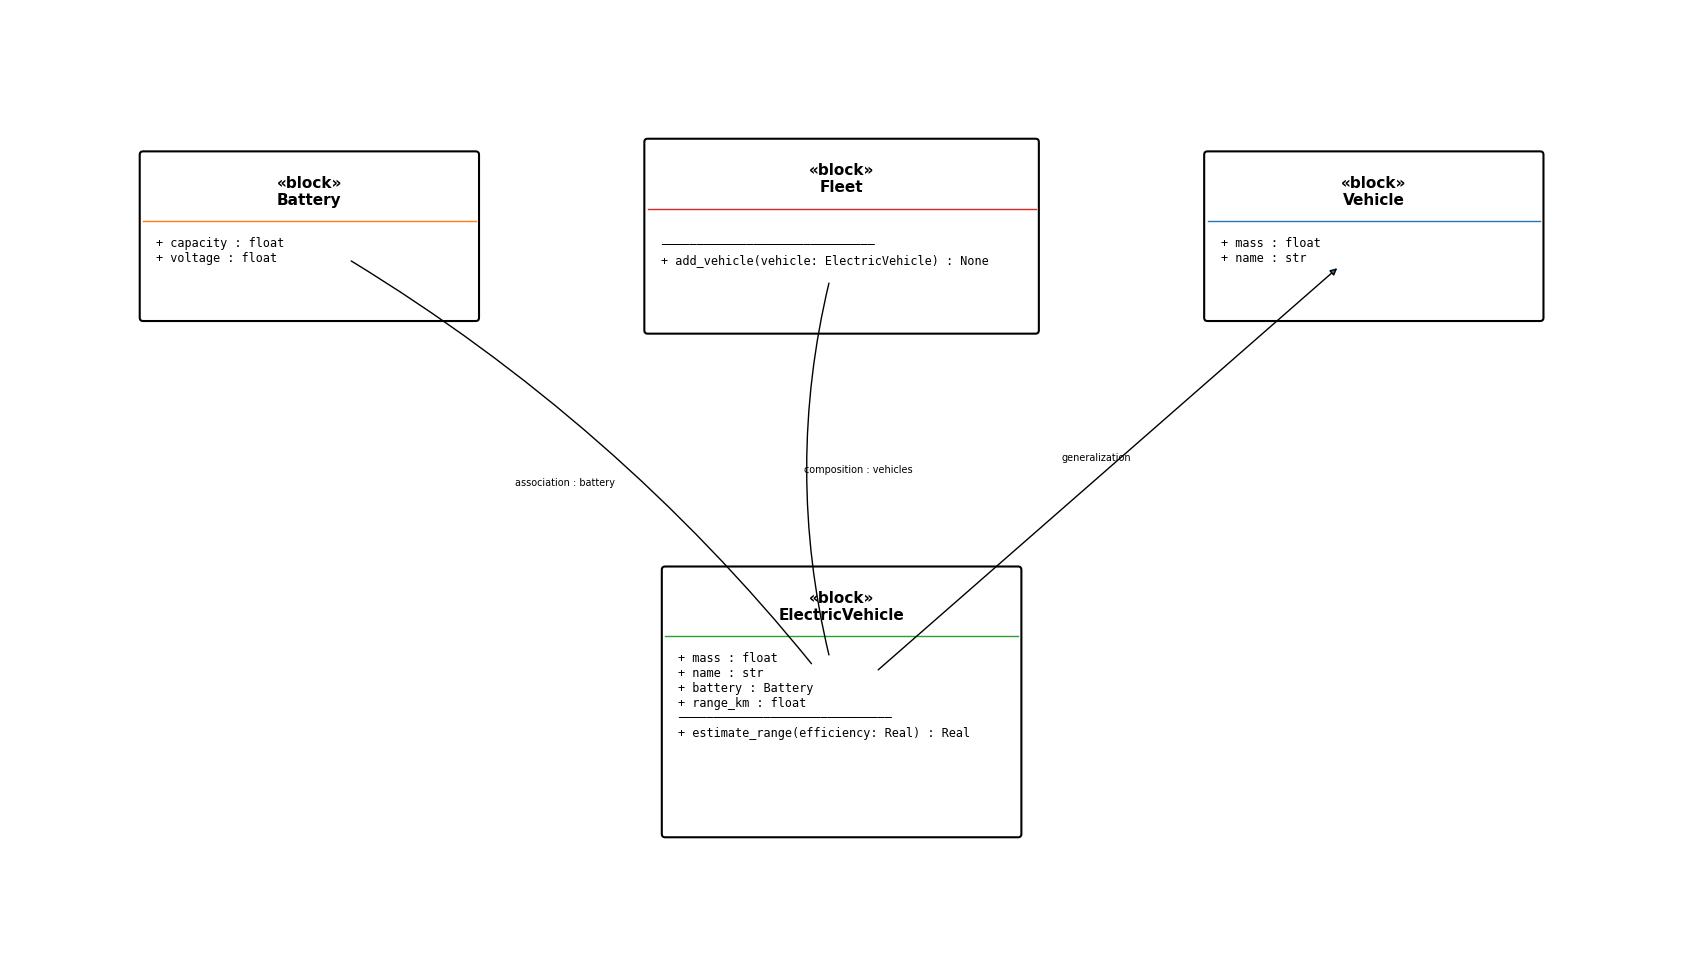

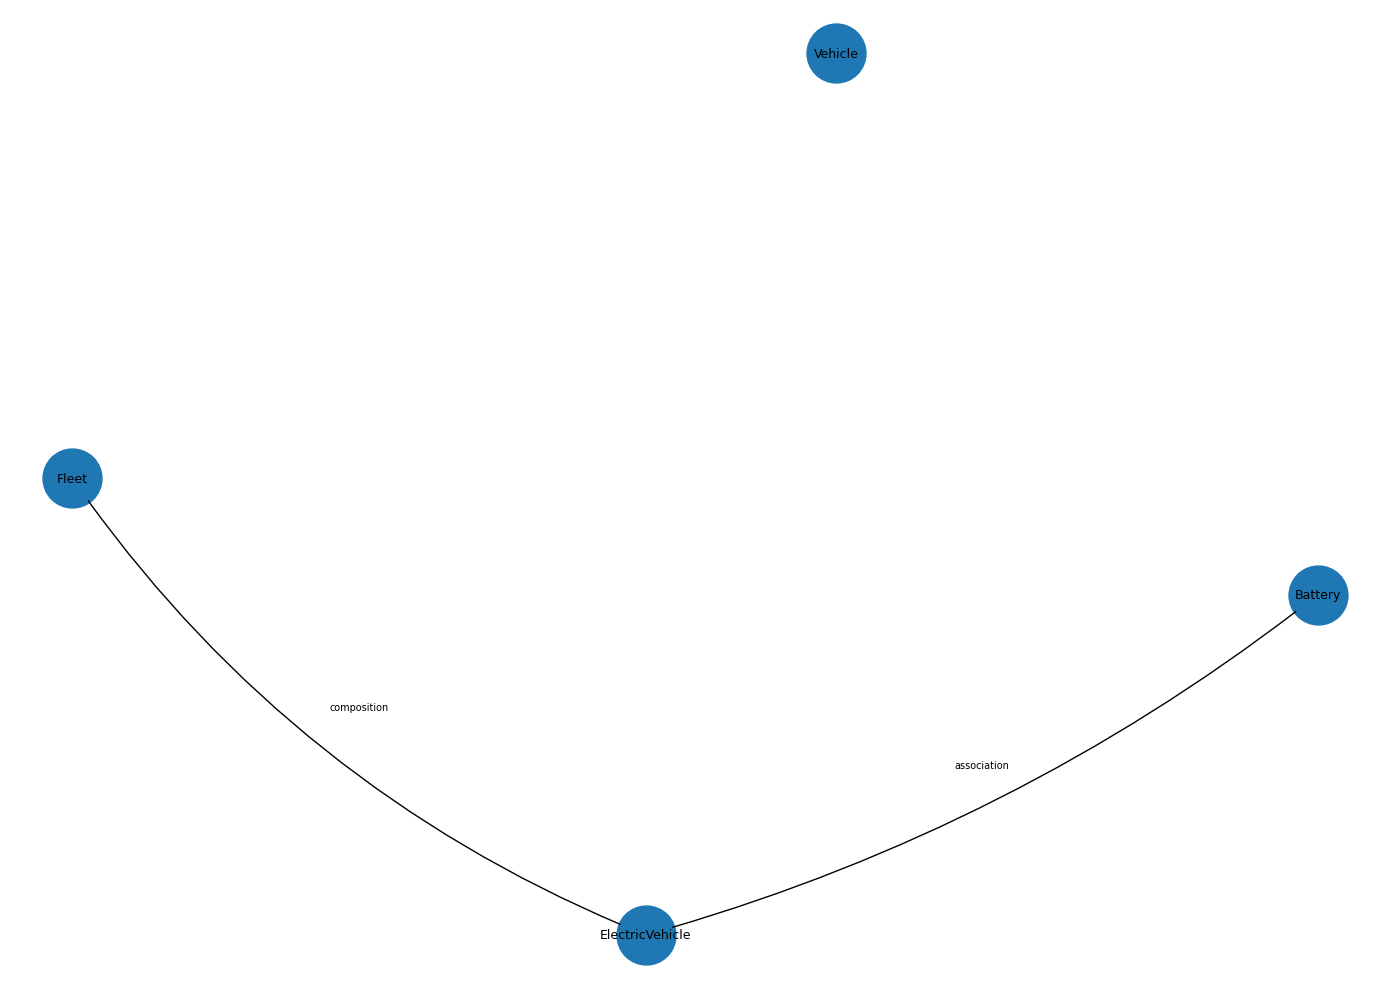

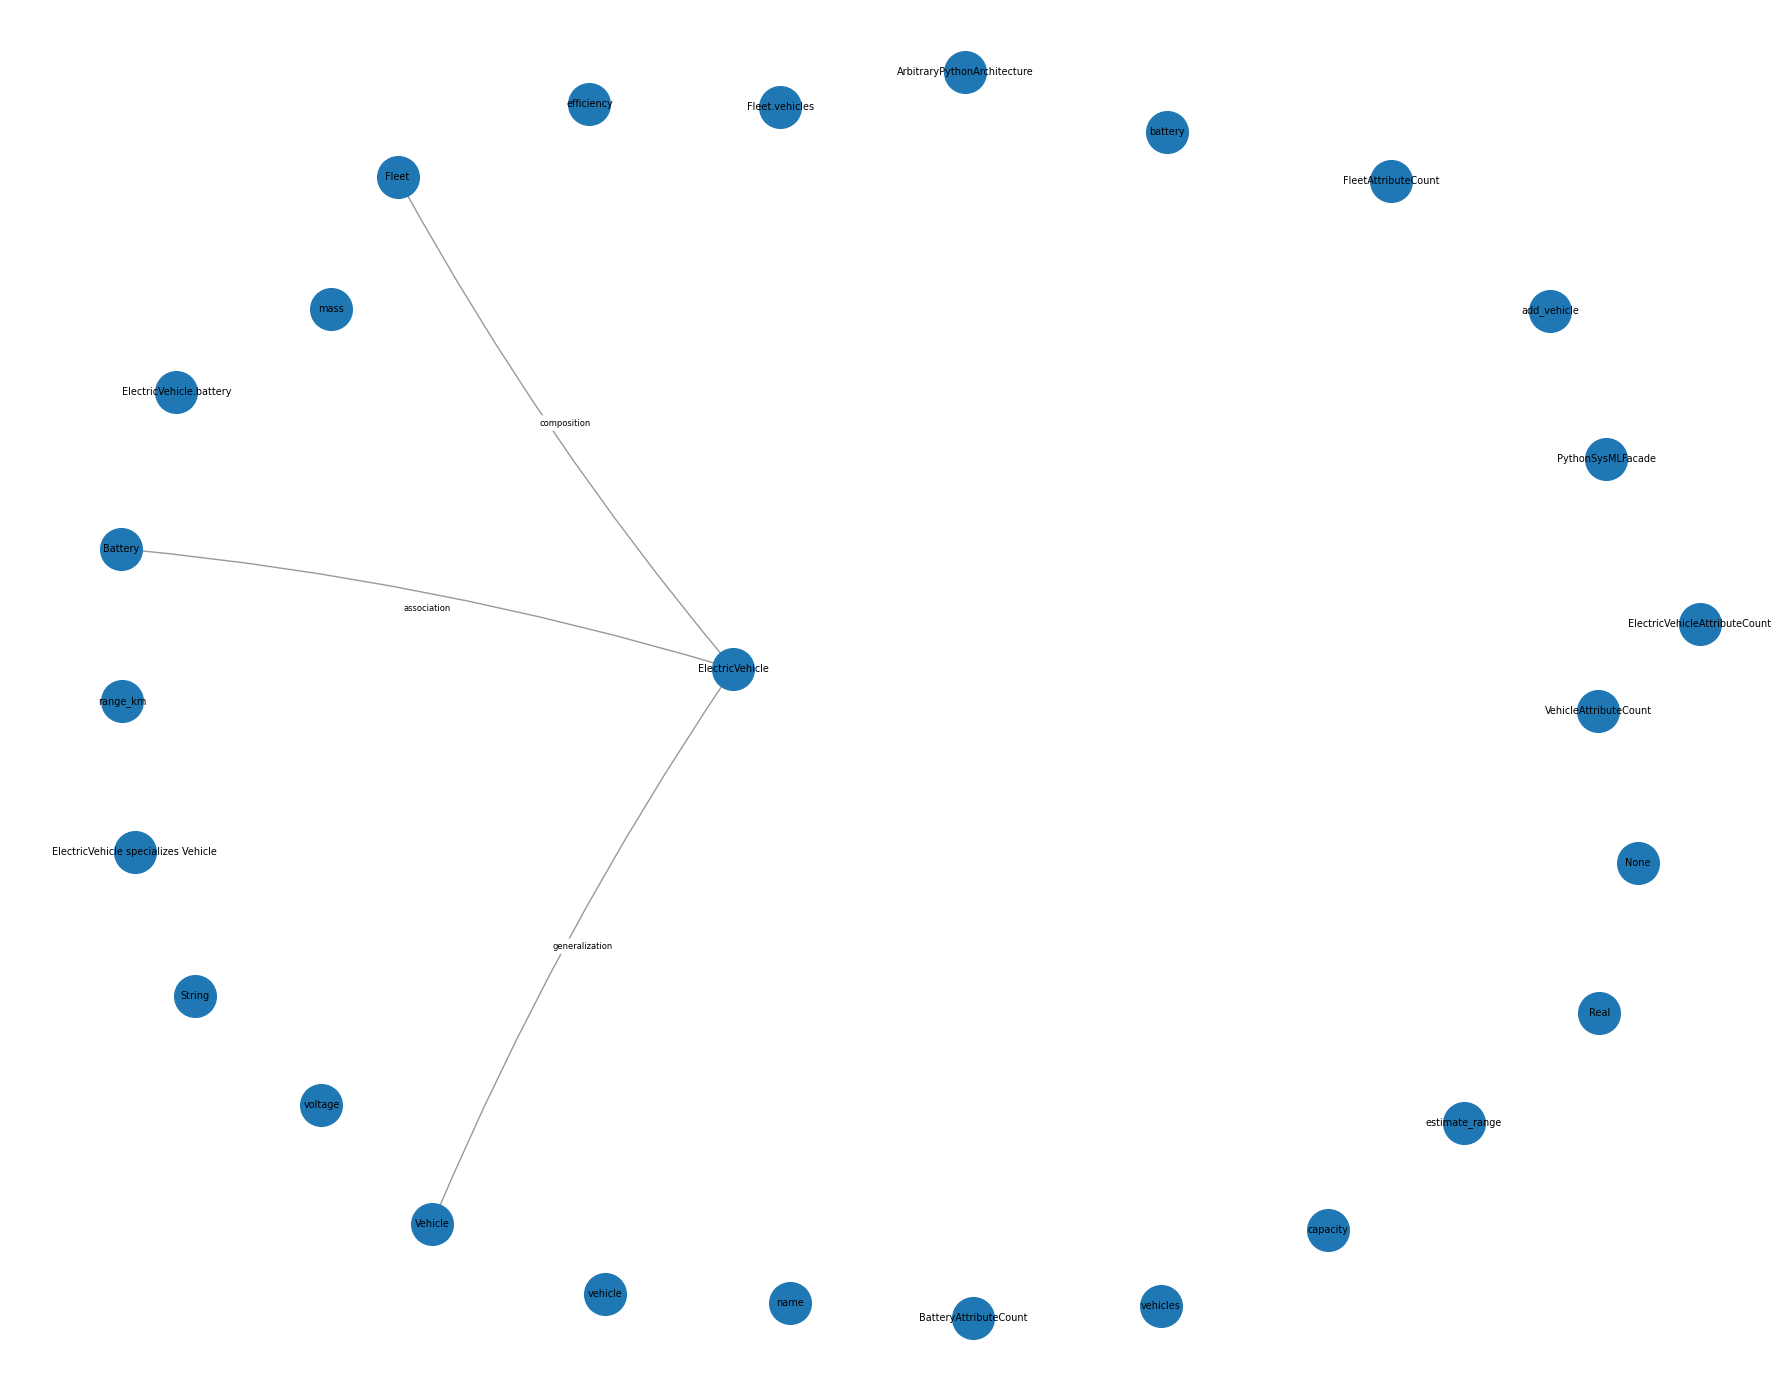

In [4]:
from cameo_sysml_transformer import SysMLTransformer, ModelPlotter
from dataclasses import dataclass

@dataclass
class Vehicle:
    """Base vehicle."""
    mass: float
    name: str

@dataclass
class Battery:
    capacity: float
    voltage: float

@dataclass
class ElectricVehicle(Vehicle):
    battery: Battery
    range_km: float = 0.0

    def estimate_range(self, efficiency: float) -> float:
        return self.battery.capacity * efficiency

class Fleet:
    vehicles: list[ElectricVehicle]
    def add_vehicle(self, vehicle: ElectricVehicle) -> None:
        pass

transformer = SysMLTransformer.from_classes(
    Vehicle,
    Battery,
    ElectricVehicle,
    Fleet,
    name="ArbitraryPythonArchitecture",
)

xmi = transformer.export_xmi("C:/Users/Drew/Documents/MyFiles/work/sysml/PythonSysML_Cameo_Interoperability.xmi")
manifest = transformer.export_json("C:/Users/Drew/Documents/MyFiles/work/sysml/PythonSysML_Cameo_Interoperability.json")

plotter = ModelPlotter(transformer.model)

fig, ax = plotter.plot_class_diagram()
fig, ax = plotter.plot_dependencies()
fix, ax = plotter.plot_model()





AttributeError: 'ModelPlotter' object has no attribute '_draw_classes'

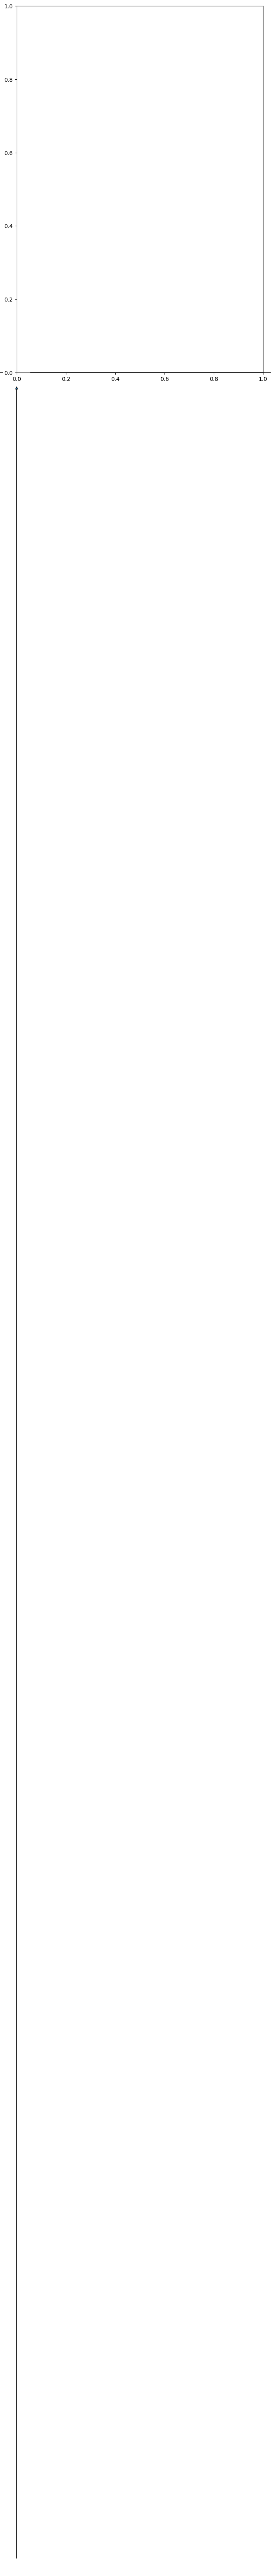

In [3]:
from cameo_sysml_transformer import XMIModelGraph, ModelPlotter

xmi = transformer.export_xmi("C:/Users/Drew/Documents/MyFiles/work/sysml/PythonSysML_Cameo_Interoperability.xmi")
manifest = transformer.export_xmi("C:/Users/Drew/Documents/MyFiles/work/sysml/PythonSysML_Cameo_Interoperability.json")
graph = XMIModelGraph(xmi)
plotter = ModelPlotter(xmi)
plotter.plot_class_diagram()